# PCA: find the main patterns in wine data

**Principal component analysis (PCA)** helps us summarize many columns with fewer new columns. These new columns are called **components**.

This is called **dimensionality reduction**: using fewer columns to describe the same rows.

Today we will:
- Load and prepare wine data.
- Use PCA to make a two-column view.
- Check how much information that view keeps.

Run the cells from top to bottom. Open this notebook from the lesson folder. It uses `../data/winequality_merged.csv` from the course repository.

*Adapted for live teaching from the lesson by Tim Book, Justin Pounders, Matt Brems, and Noelle Brown.*

## 1. Setup: load our tools

Pandas works with tables. Matplotlib draws charts. Scikit-learn provides scaling and PCA.

In [1]:
# Load the tools we need for this lesson.
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

## 2. Data ingestion: load the wine data

**Data ingestion** means loading data into Python.

Each row describes one wine sample. Most columns contain measurements, such as acidity and alcohol.

`quality` is a rating. `red_wine` tells us the wine type: 1 means red and 0 means white.

We will explore patterns in the measurements. We will not build a prediction model today.

Data: Cortez, Cerdeira, Almeida, Matos, and Reis (2009), *Modeling wine preferences by data mining from physicochemical properties*, Decision Support Systems, 47(4), 547–553.

In [2]:
# Read the CSV file and show the first five rows.
wine = pd.read_csv('../data/winequality_merged.csv')
wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,red_wine
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


## 3. Explore: check what we loaded

Check the table size and look for missing values. PCA needs complete numeric data. This file has no missing values.

In [3]:
# Count the rows, columns, and missing values.
print(f"Wine samples: {wine.shape[0]:,}")
print(f"Columns: {wine.shape[1]}")
print(f"Missing values: {wine.isna().sum().sum()}")

Wine samples: 6,497
Columns: 13
Missing values: 0


## 4. Preprocessing: choose and scale the measurements

**Preprocessing** means preparing data before using it.

We call the input columns **features**. `X` will hold the 11 measurement columns. We leave out the quality rating and wine type.

The measurements use different units. Some have much larger numbers than others. That can give them too much influence on PCA.

`StandardScaler` puts each column on a comparable scale. This is called **standardization**. It subtracts the column's average, then divides by its standard deviation, a measure of how much values differ from the average.

Unlike dividing image pixels by 255, this does not put values between 0 and 1. Negative values are normal: they mean below the original column's average.

In [4]:
# Keep the measurements for PCA. Save wine type only for coloring the chart.
X = wine.drop(columns=['quality', 'red_wine'])
wine_type = wine['red_wine']

# Learn each column's average and standard deviation, then scale its values.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Show a few scaled values with their original column names.
pd.DataFrame(X_scaled, columns=X.columns).head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,0.142473,2.188833,-2.192833,-0.744778,0.569958,-1.100140,-1.446359,1.034993,1.813090,0.193097,-0.915464
1,0.451036,3.282235,-2.192833,-0.597640,1.197975,-0.311320,-0.862469,0.701486,-0.115073,0.999579,-0.580068
2,0.451036,2.553300,-1.917553,-0.660699,1.026697,-0.874763,-1.092486,0.768188,0.258120,0.797958,-0.580068
3,3.073817,-0.362438,1.661085,-0.744778,0.541412,-0.762074,-0.986324,1.101694,-0.363868,0.327510,-0.580068
4,0.142473,2.188833,-2.192833,-0.744778,0.569958,-1.100140,-1.446359,1.034993,1.813090,0.193097,-0.915464


## 5. PCA: summarize 11 measurements with 2 components

Each component mixes information from the original columns. It is a new summary column, not one of the old measurements.

**Variation** means differences between values. **Variance** measures this variation using the average squared distance from the average value. The first component captures the most variation in the scaled data. The second captures the most remaining variation in a direction perpendicular to the first.

`fit_transform()` learns these patterns and gives each wine two new values. PCA does not see the wine-type labels.

In [5]:
# Ask PCA for two summary columns.
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# The number of wines stays the same. The number of columns gets smaller.
print(f"Before PCA: {X_scaled.shape[0]:,} rows, {X_scaled.shape[1]} columns")
print(f"After PCA:  {X_pca.shape[0]:,} rows, {X_pca.shape[1]} columns")

Before PCA: 6,497 rows, 11 columns
After PCA:  6,497 rows, 2 columns


## 6. Visualize: draw a map of the wines

Each dot is one wine. The two axes are our new components.

We add colors using the wine types we saved earlier. These labels were not used to create the components.

Look for groups and overlap. This chart is a simplified view, so it leaves out some differences between wines.

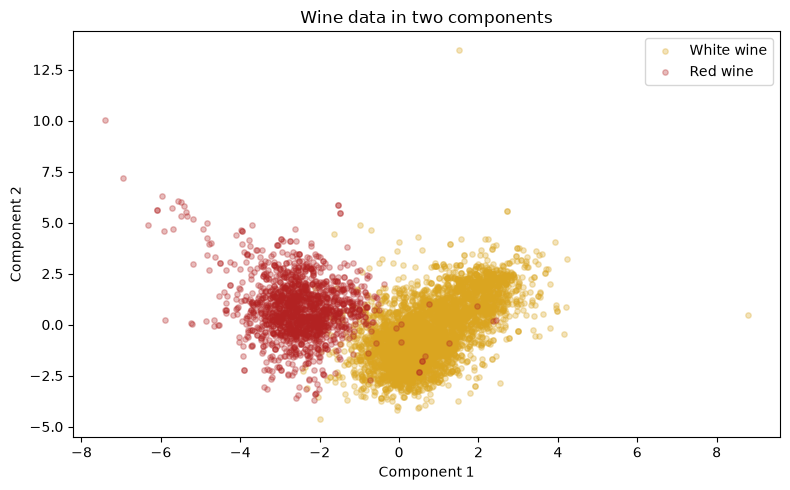

In [6]:
# Plot the two components. Add a color and label for each wine type.
fig, ax = plt.subplots(figsize=(8, 5))
for label, name, color in [(0, 'White wine', 'goldenrod'), (1, 'Red wine', 'firebrick')]:
    mask = wine_type == label
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], label=name,
               color=color, alpha=0.3, s=15)

# Label the chart so the new axes are easy to identify.
ax.set(xlabel='Component 1', ylabel='Component 2', title='Wine data in two components')
ax.legend()
plt.tight_layout()
plt.show()

### Pause and discuss

Where do the wine types overlap? Can we say that PCA learned to predict wine type?

Remember: we added the colors after PCA had already found the patterns.

## 7. Explained variance: how much do two components keep?

**Explained variance** measures how much of the variation in the scaled data a component captures.

`explained_variance_ratio_` gives the share for each component. We show it as a percentage below.

A higher total means we keep more of the variation in the scaled data. It is not a prediction accuracy score.

In [7]:
# Show the share of variation captured by each component and by both together.
for number, share in enumerate(pca.explained_variance_ratio_, start=1):
    print(f"Component {number}: {share:.1%}")
print(f"Total kept: {pca.explained_variance_ratio_.sum():.1%}")

Component 1: 27.5%
Component 2: 22.7%
Total kept: 50.2%


## 8. Choose: would more components help?

Two components are useful for drawing a chart. We may need more to keep most of the data's variation.

First, try all components. Then add their shares in order. This running total is called **cumulative explained variance**.

We will use 95% as an example goal. It is a choice, not a rule.

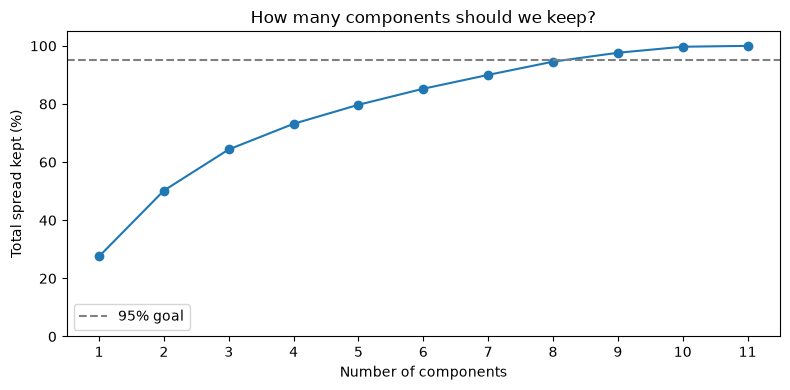

In [8]:
# Keep all components so we can compare different component counts.
pca_all = PCA()
pca_all.fit(X_scaled)

# Add the shares in order: first one, then the first two, and so on.
cumulative_share = pca_all.explained_variance_ratio_.cumsum()
component_counts = range(1, len(cumulative_share) + 1)

# Show how much variation we keep as we add components.
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(component_counts, cumulative_share * 100, marker='o')
ax.axhline(95, color='gray', linestyle='--', label='95% goal')
ax.set(xlabel='Number of components', ylabel='Total variation kept (%)',
       title='How many components should we keep?', xticks=list(component_counts), ylim=(0, 105))
ax.legend()
plt.tight_layout()
plt.show()

### Let PCA choose the number

`n_components=2` asks for exactly two components.

`n_components=0.95` asks for enough components to keep at least 95% of the variation. Scikit-learn chooses how many are needed.

In [9]:
# Choose enough components to keep at least 95% of the variation.
pca_95 = PCA(n_components=0.95)
X_pca_95 = pca_95.fit_transform(X_scaled)

# Compare this result with our two-component view.
print(f"Original columns: {X.shape[1]}")
print(f"Components kept: {pca_95.n_components_}")
print(f"Total variation kept: {pca_95.explained_variance_ratio_.sum():.1%}")

Original columns: 11
Components kept: 9
Total variation kept: 97.6%


## 9. What should we remember?

- PCA creates new summary columns. It does not just select old columns.
- Scaling matters when the original columns use different units.
- Fewer components make the data simpler, but lose some detail.
- More variation does not always mean more useful information.
- Components can be harder to explain than named measurements, such as alcohol.

We used all rows to explore this dataset. For a future prediction task, split into training and test data first. Learn the scaling and PCA steps from the training data only.

### Quick check

1. Why did we scale the measurements?
2. Did PCA use the wine-type labels?
3. Does keeping 95% of the variation mean 95% prediction accuracy?
4. Why might we use two components for a chart but more for another task?

Try changing `0.95` to `0.90` in the last code cell. Does PCA keep fewer components?